# 03 - Train models, SHAP, GNN, and text baselines

This notebook uses the exact 100,023-row mock dataset, compares the tabular ensemble, explains the LightGBM, runs an experimental graph model, and describes the independently-labeled text-training path.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from momo_fraud.io import load_tables
tables = load_tables(PROJECT_ROOT / "data" / "mock_full", PROJECT_ROOT / "configs" / "columns.yaml")
assert len(tables["transactions"]) == 100023
print("Training dataset:", len(tables["transactions"]), "transactions")

Training dataset: 100023 transactions


## Fit the tabular ensemble

In [2]:
from momo_fraud.pipeline import run_experiment
experiment = run_experiment(
    tables,
    max_fpr=0.01,
    random_state=7,
    model_dir=PROJECT_ROOT / "models",
    report_dir=PROJECT_ROOT / "reports" / "metrics",
    processed_dir=PROJECT_ROOT / "data" / "processed",
    decision_config=PROJECT_ROOT / "configs" / "decision.yaml",
    feature_config=PROJECT_ROOT / "configs" / "features.yaml",
)
report = experiment["report"]
print("Tree:", report["tree_implementation"])
print("Rows:", report["rows"])
print("Latency:", report["latency_benchmark"])

Tree: LGBMClassifier
Rows: {'all_transactions': 100023, 'excluded_boundary_case_rows': 123, 'train': 59974, 'validation': 19947, 'test': 19979}
Latency: {'scope': 'warmed in-process scoring; excludes feature construction and network', 'transactions': 200, 'p50_ms': 31.28440002910793, 'p95_ms': 51.29821999871637, 'p99_ms': 130.20868102903475}


## Tabular model comparison

In [3]:
import pandas as pd
metric_names = ["pr_auc", "roc_auc", "precision", "recall", "false_positive_rate", "amount_weighted_recall", "amount_stopped"]
display(pd.DataFrame({name: {key: values[key] for key in metric_names}
                      for name, values in report["models"].items()}).T)

,pr_auc,roc_auc,precision,recall,false_positive_rate,amount_weighted_recall,amount_stopped
rules,0.490166,0.749330,1.0,0.030969,0.0,0.071418,634176.05
logistic,0.987218,0.995508,1.0,0.015709,0.0,0.010541,93605.90
gradient_boosted,0.992576,0.997646,0.0,0.000000,0.0,0.000000,0.00
ensemble_calibrated,0.994518,0.997841,1.0,0.512343,0.0,0.632918,5620202.35


## SHAP feature importance

SHAP explains the LightGBM component. It is a model-attribution aid, not a substitute for transaction reason codes.

,feature,mean_abs_shap
0,payee_account_age_days,2.456307
1,fee,1.042107
2,payee_unique_senders_7d,0.690111
3,type_cash_in,0.473491
4,amount,0.466685
5,anomaly_score,0.422417
6,payee_in_amount_24h,0.299940
7,payer_amount_mean_30d,0.298816
8,amount_vs_payer_mean,0.200635
9,payer_out_amount_24h,0.171099


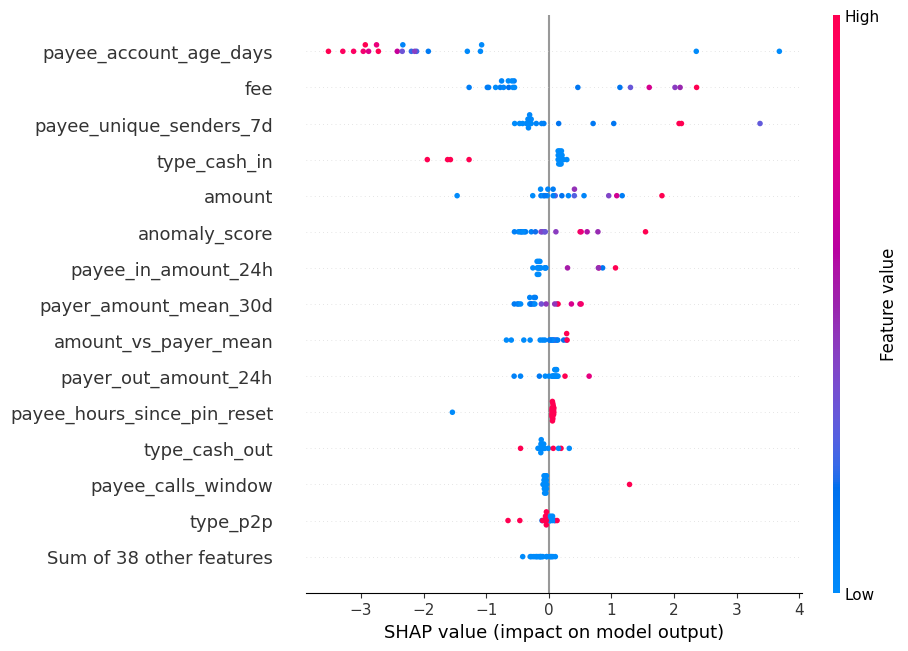

In [4]:
import shap
from momo_fraud.features.state import NUMBER_COLUMNS
from momo_fraud.models.anomaly import anomaly_score
from momo_fraud.explain import shap_importance, tree_shap_values

feature_table = experiment["features"].set_index("tx_id")
X = feature_table.loc[:, list(NUMBER_COLUMNS)].astype(float)
bundle = experiment["models"]
X["anomaly_score"] = anomaly_score(bundle["anomaly"], X)
assignment = experiment["assignment"]
train_ids = assignment.index[assignment == "train"]
test_ids = assignment.index[assignment == "test"]
background = X.loc[train_ids].sample(n=min(30, len(train_ids)), random_state=7)
examples = X.loc[test_ids].sample(n=min(20, len(test_ids)), random_state=7)
explanation = tree_shap_values(bundle["gradient_boosted"], background, examples)
display(shap_importance(explanation, limit=20))
shap.plots.beeswarm(explanation, max_display=15)

## Experimental GraphSAGE comparison

This uses a fixed graph built from the training split and scores validation/test edges against that snapshot. It is not an online, point-in-time GNN.

In [5]:
from momo_fraud.evaluate import evaluate_predictions, threshold_at_fpr
from momo_fraud.models.gnn import fit_graph_model

transactions = tables["transactions"].set_index("tx_id", drop=False)
assignment = experiment["assignment"]
feature_table = experiment["features"].set_index("tx_id")
base_features = feature_table.loc[:, list(NUMBER_COLUMNS)]
train_ids = assignment.index[assignment == "train"]
validation_ids = assignment.index[assignment == "validation"]
test_ids = assignment.index[assignment == "test"]
train_tx = transactions.loc[train_ids].reset_index(drop=True)
validation_tx = transactions.loc[validation_ids].reset_index(drop=True)
test_tx = transactions.loc[test_ids].reset_index(drop=True)

graph_model = fit_graph_model(
    train_tx,
    base_features.loc[train_ids],
    train_tx["is_fraud"].astype(int),
    feature_columns=list(NUMBER_COLUMNS),
    epochs=4,
    hidden=16,
)
validation_probability = graph_model.predict_proba(validation_tx, base_features.loc[validation_ids])
test_probability = graph_model.predict_proba(test_tx, base_features.loc[test_ids])
graph_threshold = threshold_at_fpr(validation_tx["is_fraud"].astype(int), validation_probability, max_fpr=0.01)
graph_metrics = evaluate_predictions(
    test_tx["is_fraud"].astype(int), test_probability, test_tx["amount"].astype(float),
    graph_threshold, fraud_kinds=test_tx["fraud_scenario"],
)
display({key: graph_metrics[key] for key in ["pr_auc", "precision", "recall", "false_positive_rate", "amount_weighted_recall"]})

{'pr_auc': 0.8638692865492542,
 'precision': 1.0,
 'recall': 0.0002244165170556553,
 'false_positive_rate': 0.0,
 'amount_weighted_recall': 0.00011684348571671356}

## Text baseline and transformer path

The mock texts do not provide independent message labels. Do not train a transformer using the synthetic fraud scenario as the text label. When a reviewed `data/raw/text_labels.csv` file exists with `text`, `is_fraud`, `split`, and preferably `fraud_case`, use `scripts/train_text_transformer.py`.

In [6]:
text_labels = PROJECT_ROOT / "data" / "raw" / "text_labels.csv"
if text_labels.is_file():
    print("Independent text labels found:", text_labels)
else:
    print("Transformer training skipped: no independently labeled text dataset at", text_labels)

Transformer training skipped: no independently labeled text dataset at C:\Users\yasmine\Desktop\Momo fraud hackathon\FDE\data\raw\text_labels.csv
